# Clustering du jeu de données Wine (UCI) : Kmeans et CAH

Objectif : regrouper des vins selon leur composition chimique, sans utiliser leur cultivar, avec deux méthodes (**Kmeans** et **CAH**), les comparer, puis déployer le meilleur modèle.

Ce notebook reprend la structure des notebooks du prof  **Standardisation** (`StandardScaler`) à la place de `normalize` : voir la section « Choix de la mise à l'échelle ».
2. **Liaison de Ward** pour la CAH à la place de `average` : les deux sont comparées dans la section CAH.
3. **`random_state` et `n_init`** dans KMeans (résultats reproductibles), et dendrogramme tronqué pour rester lisible.

### <font color='gold'> Importer les librairies requises

In [26]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px

In [27]:
# Supprimer les warnings
import warnings
warnings.filterwarnings('ignore')

### <font color='gold'> Importer et lire les données

**Source (UCI Machine Learning Repository) :** [Wine](https://archive.ics.uci.edu/dataset/109/wine) (page de description du jeu de données).

Ces données sont le résultat d'une analyse chimique de vins produits dans une même région d'Italie, à partir de **3 cultivars** différents. Chaque vin est décrit par **13 variables** chimiques. Le fichier `wine.data` n'a pas d'en-tête : la 1re colonne est la classe (le cultivar), les 13 autres sont les mesures.

In [28]:
# Noms des variables (d'après wine.names). La 1re colonne du fichier est la classe (cultivar).
colonnes = ['Alcohol', 'Malic acid', 'Ash', 'Alcalinity of ash', 'Magnesium', 'Total phenols',
            'Flavanoids', 'Nonflavanoid phenols', 'Proanthocyanins', 'Color intensity', 'Hue',
            'OD280/OD315', 'Proline']

# Lire le fichier CSV
df = pd.read_csv('wine.csv', header=None, names=['class'] + colonnes)

#### Description des variables du jeu de données « Wine »

| Variable | Description |
|----------|-------------|
| `Class` | Cultivar du vin (1, 2 ou 3). **Non utilisée pour le clustering**, gardée pour comparer. |
| `Alcohol` | Degré d'alcool. |
| `Malic acid` | Acide malique. |
| `Ash` | Cendres. |
| `Alcalinity of ash` | Alcalinité des cendres. |
| `Magnesium` | Magnésium. |
| `Total phenols` | Phénols totaux. |
| `Flavanoids` | Flavonoïdes. |
| `Nonflavanoid phenols` | Phénols non flavonoïdes. |
| `Proanthocyanins` | Proanthocyanidines. |
| `Color intensity` | Intensité de la couleur. |
| `Hue` | Teinte. |
| `OD280/OD315` | Rapport de densité optique des vins dilués (OD280/OD315). |
| `Proline` | Proline. |

In [29]:
# Afficher les données
df.head()

,class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [30]:
# Dimension des données
df.shape

(178, 14)

In [31]:
# Infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   class                 178 non-null    int64  
 1   Alcohol               178 non-null    float64
 2   Malic acid            178 non-null    float64
 3   Ash                   178 non-null    float64
 4   Alcalinity of ash     178 non-null    float64
 5   Magnesium             178 non-null    int64  
 6   Total phenols         178 non-null    float64
 7   Flavanoids            178 non-null    float64
 8   Nonflavanoid phenols  178 non-null    float64
 9   Proanthocyanins       178 non-null    float64
 10  Color intensity       178 non-null    float64
 11  Hue                   178 non-null    float64
 12  OD280/OD315           178 non-null    float64
 13  Proline               178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [32]:
# Décrire les données
df.describe().T

,count,mean,std,min,25%,50%,75%,max
class,178.0,1.938202,0.775035,1.00,1.0000,2.000,3.0000,3.00
Alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
Malic acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
Ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
Alcalinity of ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
Magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
Total phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
Flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
Nonflavanoid phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
Proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58


Nettoyage du jeu de données

In [33]:
# Valeurs manquantes, doublons et types des variables
print("Valeurs manquantes :", df.isna().sum().sum())
print("Lignes dupliquées  :", df.duplicated().sum())
print(df.dtypes.value_counts())

Valeurs manquantes : 0
Lignes dupliquées  : 0
float64    11
int64       3
Name: count, dtype: int64


**Constat :** aucune valeur manquante, aucun doublon, et toutes les variables sont numériques. Le jeu de données ne demande donc pas de nettoyage supplémentaire. Il faut seulement **retirer la colonne `Class`** (le cultivar) des variables utilisées pour le clustering : on la garde à part dans `y` pour comparer les classes trouvées avec la réalité.

In [34]:
# Mettre la classe réelle (cultivar) à part : elle ne sert pas au clustering
y = df['class']
df = df.drop(columns='class')

In [35]:
# Renommer les index
df.index = [f"Vin{i+1}" for i in range(len(df))]
y.index = df.index
df.head()

,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315,Proline
Vin1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
Vin2,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
Vin3,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
Vin4,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
Vin5,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


Exploration rapide : corrélations

In [36]:
# Matrice de corrélation des variables
fig = px.imshow(df.corr().round(2), color_continuous_scale='RdBu_r', zmin=-1, zmax=1, aspect='auto')
fig.show()

Préparation des données

Les variables n'ont pas du tout la même échelle (la `Proline` vaut environ 750 en moyenne et le `Magnesium` environ 100, alors que la plupart des autres variables valent entre 0 et 20). Sans standardisation, `Proline` et `Magnesium` domineraient les distances et donc le clustering. On **standardise** donc chaque variable (moyenne 0, écart-type 1).

In [37]:
# Écart-type de chaque variable (les échelles sont très différentes)
df.std().round(3)

Alcohol                   0.812
Malic acid                1.117
Ash                       0.274
Alcalinity of ash         3.340
Magnesium                14.282
Total phenols             0.626
Flavanoids                0.999
Nonflavanoid phenols      0.124
Proanthocyanins           0.572
Color intensity           2.318
Hue                       0.229
OD280/OD315               0.710
Proline                 314.907
dtype: float64

In [38]:
# Données en format matriciel
x = df.values
x[:5]

array([[1.423e+01, 1.710e+00, 2.430e+00, 1.560e+01, 1.270e+02, 2.800e+00,
        3.060e+00, 2.800e-01, 2.290e+00, 5.640e+00, 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, 1.120e+01, 1.000e+02, 2.650e+00,
        2.760e+00, 2.600e-01, 1.280e+00, 4.380e+00, 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, 1.860e+01, 1.010e+02, 2.800e+00,
        3.240e+00, 3.000e-01, 2.810e+00, 5.680e+00, 1.030e+00, 3.170e+00,
        1.185e+03],
       [1.437e+01, 1.950e+00, 2.500e+00, 1.680e+01, 1.130e+02, 3.850e+00,
        3.490e+00, 2.400e-01, 2.180e+00, 7.800e+00, 8.600e-01, 3.450e+00,
        1.480e+03],
       [1.324e+01, 2.590e+00, 2.870e+00, 2.100e+01, 1.180e+02, 2.800e+00,
        2.690e+00, 3.900e-01, 1.820e+00, 4.320e+00, 1.040e+00, 2.930e+00,
        7.350e+02]])

In [39]:
# Importer StandardScaler
from sklearn.preprocessing import StandardScaler
# Standardiser x (moyenne 0, écart-type 1 pour chaque variable)
scaler = StandardScaler()
x = scaler.fit_transform(x)
x[:5]

array([[ 1.51861254, -0.5622498 ,  0.23205254, -1.16959318,  1.91390522,
         0.80899739,  1.03481896, -0.65956311,  1.22488398,  0.25171685,
         0.36217728,  1.84791957,  1.01300893],
       [ 0.24628963, -0.49941338, -0.82799632, -2.49084714,  0.01814502,
         0.56864766,  0.73362894, -0.82071924, -0.54472099, -0.29332133,
         0.40605066,  1.1134493 ,  0.96524152],
       [ 0.19687903,  0.02123125,  1.10933436, -0.2687382 ,  0.08835836,
         0.80899739,  1.21553297, -0.49840699,  2.13596773,  0.26901965,
         0.31830389,  0.78858745,  1.39514818],
       [ 1.69154964, -0.34681064,  0.4879264 , -0.80925118,  0.93091845,
         2.49144552,  1.46652465, -0.98187536,  1.03215473,  1.18606801,
        -0.42754369,  1.18407144,  2.33457383],
       [ 0.29570023,  0.22769377,  1.84040254,  0.45194578,  1.28198515,
         0.80899739,  0.66335127,  0.22679555,  0.40140444, -0.31927553,
         0.36217728,  0.44960118, -0.03787401]])

Appliquer une ACP (pour visualiser les classes en 2D)

In [40]:
# Importer PCA
from sklearn.decomposition import PCA
# Instantier le modèle PCA avec n_components = 2
pca = PCA(n_components=2)
# Matrice des 2 composantes
features_pca = pca.fit_transform(x)
# Dataframe
New_df = pd.DataFrame(features_pca, columns=['PC1', 'PC2'])

In [41]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_ * 100), 2)

np.float64(55.41)

Choix de la mise à l'échelle : `normalize` ou `StandardScaler` ?

In [42]:
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

versions = {'normalize ': normalize(df.values), 'StandardScaler (retenu)': x}
for nom, X in versions.items():
    part = KMeans(n_clusters=3, init='random', max_iter=500, n_init=10, random_state=42).fit_predict(X)
    var_acp = PCA(n_components=2).fit(X).explained_variance_ratio_.sum() * 100
    print(f"{nom:26s} variance ACP (2 comp.) = {var_acp:5.1f} %   silhouette = {silhouette_score(X, part):.3f}   "
          f"accord avec les cultivars (Rand ajusté) = {adjusted_rand_score(y, part):.3f}")

normalize                  variance ACP (2 comp.) =  99.1 %   silhouette = 0.523   accord avec les cultivars (Rand ajusté) = 0.347
StandardScaler (retenu)    variance ACP (2 comp.) =  55.4 %   silhouette = 0.285   accord avec les cultivars (Rand ajusté) = 0.897


**Lecture du résultat.** Avec `normalize`, chaque vin est ramené à une norme 1 **sans égaliser les variables** : la `Proline` (environ 750) écrase les autres, et les deux premières composantes de l'ACP résument à elles seules environ 99 % de la variance, c'est-à-dire presque une seule variable. La silhouette paraît meilleure (environ 0,52 contre 0,29), mais **elle n'est pas comparable d'un espace à l'autre**, et l'accord avec les cultivars s'effondre (environ 0,35 contre 0,90). On garde donc `StandardScaler`, qui donne le même poids à chacune des 13 variables.

 Fonctions utiles

- `ordonner` : les numéros de classes donnés par KMeans ou la CAH sont arbitraires (la classe « 0 » peut changer d'une exécution à l'autre). On les renumérote donc par ordre croissant de la moyenne de la variable `Proline` : la classe 0 est celle où `Proline` est le plus faible. Les classes ont ainsi toujours le même numéro.
- `bar_plot` et `scatter_plot` : les deux graphiques utilisés pour chaque modèle.

In [43]:
# Renuméroter les classes par moyenne croissante d'une variable
def ordonner(partition, variable='Proline'):
    moyennes = df.groupby(partition)[variable].mean().sort_values()
    ordre = {ancienne: nouvelle for nouvelle, ancienne in enumerate(moyennes.index)}
    return np.array([ordre[c] for c in partition])

# Diagramme en barres du nombre d'observations dans chaque classe
def bar_plot(val):
    fig = px.bar(x=val.index.astype(str), y=val.values, color=val.index.astype(str), text_auto=True,
                 labels={'x': 'Classe', 'y': "Nombre d'observations", 'color': 'Classe'})
    fig.show()

# Visualisation des classes dans le plan des deux composantes de l'ACP
def scatter_plot(New_df, Pred):
    fig = px.scatter(New_df, x='PC1', y='PC2', color=Pred.astype(str), labels={'color': 'Classe'})
    fig.show()

Kmeans

In [44]:
# Importer KMeans
from sklearn.cluster import KMeans

##### <font color='bisque'> La méthode elbow (coude)

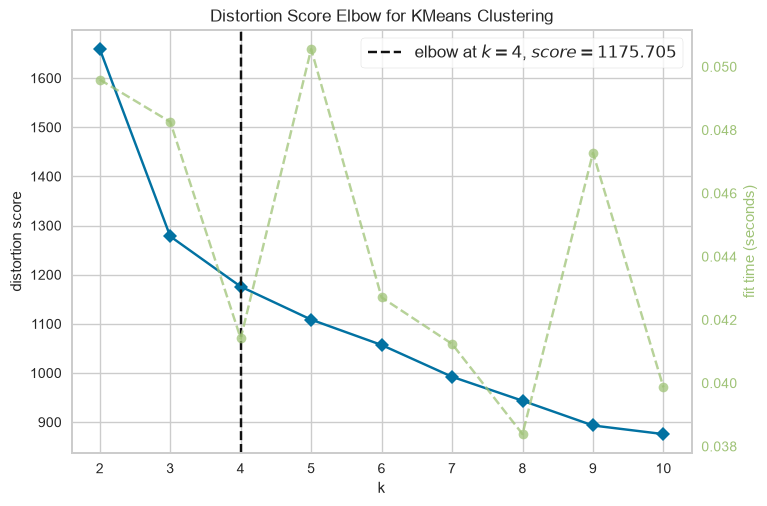

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [45]:
# Importer KElbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans (random_state et n_init pour des résultats reproductibles)
kmeans_model = KMeans(init='random', max_iter=500, n_init=10, random_state=42)
# Instantier KElbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10, force_model=True)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

##### <font color='bisque'> Indice de silhouette selon k

In [46]:
# Importer silhouette_score
from sklearn.metrics import silhouette_score
# Silhouette de KMeans pour k = 2, ..., 10
ks = list(range(2, 11))
sil_ks = []
for k in ks:
    part = KMeans(n_clusters=k, init='random', max_iter=500, n_init=10, random_state=42).fit_predict(x)
    sil_ks.append(silhouette_score(x, part))
fig = px.line(x=ks, y=sil_ks, markers=True, labels={'x': 'k (nombre de classes)', 'y': 'Silhouette'})
fig.show()

**Choix de k = 3.** Le coude n'est pas très marqué, mais l'indice de silhouette est maximal pour k = 3, ce qui correspond aussi aux 3 cultivars du jeu de données.

#### <font color='bisque'> Appliquer Kmeans en utilisant le k optimal

In [47]:
# Initier le modèle
kmeans_model = KMeans(n_clusters=3, init='random', max_iter=500, n_init=10, random_state=42)
# Entrainer le modèle
kmeans_model.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",500
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 13)","[[ 0.16

#### <font color='bisque'> Prédiction de la partition

In [48]:
# Prédiction de la partition (l'ensemble des classes) de x, avec des numéros de classes ordonnés
kmeans_partition = ordonner(kmeans_model.predict(x))
# Afficher les 50 premiers éléments
kmeans_partition[:50]

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2])

In [49]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts().sort_index()
val

0    65
1    51
2    62
Name: count, dtype: int64

In [50]:
# Diagramme en barres du nombre d'observations
bar_plot(val)

#### <font color='bisque'> Visualiser les classes prédites par Kmeans

In [51]:
# Visualiser les classes suivant les deux composantes
scatter_plot(New_df, kmeans_partition)

 Indice de silhouette de la partition du Kmeans

In [52]:
# Indice de silhouette
sil_kmeans = silhouette_score(x, kmeans_partition)
print(f"La silhouette de Kmeans est : {sil_kmeans}")

La silhouette de Kmeans est : 0.2848589191898987


Profil moyen de chaque classe et comparaison avec les cultivars

In [53]:
# Profil moyen de chaque classe (variables en lignes, classes en colonnes)
df.groupby(kmeans_partition).mean().round(2).T

,0,1,2
Alcohol,12.25,13.13,13.68
Malic acid,1.90,3.31,2.00
Ash,2.23,2.42,2.47
Alcalinity of ash,20.06,21.24,17.46
Magnesium,92.74,98.67,107.97
Total phenols,2.25,1.68,2.85
Flavanoids,2.05,0.82,3.00
Nonflavanoid phenols,0.36,0.45,0.29
Proanthocyanins,1.62,1.15,1.92
Color intensity,2.97,7.23,5.45


In [54]:
# Comparer les classes trouvées avec les cultivars réels (colonnes : cultivars 1, 2, 3)
print(pd.crosstab(kmeans_partition, y, rownames=['Classe Kmeans'], colnames=['Cultivar']))

# Indice de Rand ajusté (1 = accord parfait avec les cultivars)
from sklearn.metrics import adjusted_rand_score
print("Indice de Rand ajusté Kmeans / cultivars :", round(adjusted_rand_score(y, kmeans_partition), 3))

Cultivar        1   2   3
Classe Kmeans            
0               0  65   0
1               0   3  48
2              59   3   0
Indice de Rand ajusté Kmeans / cultivars : 0.897


**Interprétation des classes de Kmeans** (profil moyen ci-dessus) :

- **Classe 0** : vins « légers », avec l'alcool et la proline les plus faibles et une couleur peu intense.
- **Classe 1** : vins très colorés, riches en acide malique, pauvres en flavonoïdes et à teinte faible.
- **Classe 2** : vins « corsés », avec beaucoup d'alcool, de proline et de flavonoïdes.

Chaque classe correspond presque exactement à un cultivar : Kmeans retrouve la structure réelle sans l'avoir vue.

 CAH

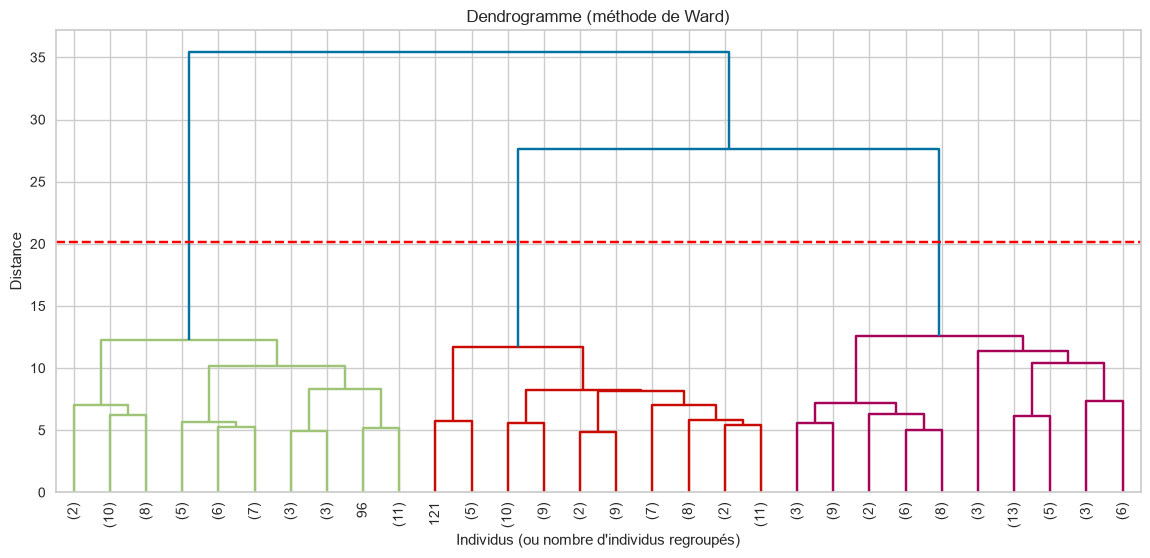

In [55]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Matrice des liaisons (méthode de Ward)
Z = linkage(x, method='ward')

# Visualiser le dendrogramme (tronqué aux 30 derniers regroupements pour rester lisible)
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10)

# Ligne rouge : coupure donnant 3 classes
seuil = (Z[-(3 - 1), 2] + Z[-3, 2]) / 2
plt.axhline(y=seuil, color='red', linestyle='--')
plt.title('Dendrogramme (méthode de Ward)')
plt.xlabel("Individus (ou nombre d'individus regroupés)")
plt.ylabel('Distance')
plt.show()

Choix de la méthode de liaison

In [56]:
# Importer AgglomerativeClustering
from sklearn.cluster import AgglomerativeClustering

# Comparer plusieurs méthodes de liaison pour le même nombre de classes
for lien in ['ward', 'average', 'complete', 'single']:
    part = AgglomerativeClustering(n_clusters=3, linkage=lien).fit_predict(x)
    print(f"{lien:9s} silhouette = {silhouette_score(x, part):.3f}   effectifs = {np.bincount(part)}")

ward      silhouette = 0.277   effectifs = [58 56 64]
average   silhouette = 0.158   effectifs = [174   1   3]
complete  silhouette = 0.204   effectifs = [69 58 51]
single    silhouette = 0.183   effectifs = [174   3   1]


**Choix de la liaison.** Les liaisons `average` et `single` isolent quelques vins extrêmes dans des classes de 1 à 3 vins et mettent tout le reste dans une seule classe, ce qui ne segmente pas vraiment les données. La liaison `complete` donne des classes équilibrées mais une silhouette plus faible. La liaison de **Ward** donne des classes équilibrées avec la meilleure silhouette ; c'est celle qu'on retient.

In [57]:
# Initier AgglomerativeClustering (liaison de Ward)
cah_model = AgglomerativeClustering(n_clusters=3, linkage='ward')
# Entrainer le modèle
cah_model.fit(x)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",3
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" and ""l2"" are accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and metric is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False
Name,Type,Value
"children_ children_: array-like of shape (n_samples-1, 2)The children of each non-leaf node. Values less than `n_samples`correspond to leaves of the tree which are the original samples.A node `i` greater than or equal to `n_samples

In [58]:
# Prédire la partition des données (numéros de classes ordonnés)
cah_partition = ordonner(cah_model.fit_predict(x))

# Afficher les 50 premiers éléments
cah_partition[:50]

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2])

In [59]:
# Nombre d'observations dans chaque classe
val1 = pd.Series(cah_partition).value_counts().sort_index()
val1

0    58
1    56
2    64
Name: count, dtype: int64

In [60]:
# Diagramme en barres des nombres d'observations
bar_plot(val1)

In [61]:
# Visualiser les classes
scatter_plot(New_df, cah_partition)

In [62]:
# Indice de silhouette
sil_cah = silhouette_score(x, cah_partition)
print(f"La silhouette de CAH est : {sil_cah}")

La silhouette de CAH est : 0.2774439826952265


In [63]:
# Profil moyen de chaque classe de la CAH
df.groupby(cah_partition).mean().round(2).T

,0,1,2
Alcohol,12.20,13.06,13.67
Malic acid,1.94,3.17,1.97
Ash,2.22,2.41,2.46
Alcalinity of ash,20.21,21.00,17.53
Magnesium,92.55,99.86,106.16
Total phenols,2.26,1.69,2.85
Flavanoids,2.09,0.85,3.01
Nonflavanoid phenols,0.36,0.45,0.29
Proanthocyanins,1.69,1.13,1.91
Color intensity,2.90,6.85,5.45


In [64]:
# Comparer les classes de la CAH avec les cultivars réels
print(pd.crosstab(cah_partition, y, rownames=['Classe CAH'], colnames=['Cultivar']))
print("Indice de Rand ajusté CAH / cultivars :", round(adjusted_rand_score(y, cah_partition), 3))

Cultivar     1   2   3
Classe CAH            
0            0  58   0
1            0   8  48
2           59   5   0
Indice de Rand ajusté CAH / cultivars : 0.79


Comparaison de Kmeans et de la CAH

In [65]:
# Diagramme en barres des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x=Model_Names, y=sil, color=Model_Names, text_auto=True,
             labels={'x': 'Modèle', 'y': 'Silhouette', 'color': 'Modèle'})
fig.show()

In [66]:
# Accord entre les deux partitions (1 = partitions identiques, 0 = accord dû au hasard)
from sklearn.metrics import adjusted_rand_score
print("Indice de Rand ajusté KMeans / CAH :", round(adjusted_rand_score(kmeans_partition, cah_partition), 3))

# Tableau croisé des deux partitions
pd.crosstab(kmeans_partition, cah_partition, rownames=['KMeans'], colnames=['CAH'])

Indice de Rand ajusté KMeans / CAH : 0.853


CAH,0,1,2
KMeans,,,
0,57,5,3
1,0,51,0
2,1,0,61


**Conclusion.** Les deux méthodes donnent des partitions proches (indice de Rand ajusté élevé) et des silhouettes voisines : la structure en 3 groupes est donc robuste. Kmeans obtient une silhouette légèrement supérieure et retrouve mieux les cultivars réels ; c'est le modèle déployé ci-dessous.

In [67]:
# Les individus de chaque classe (partition de la CAH)
cluster_names = []
for i in range(3):
    cluster_names.append(list(df.index[cah_partition == i]))

# Les 20 premiers individus de la classe 0
print(cluster_names[0][:20])

['Vin60', 'Vin63', 'Vin64', 'Vin65', 'Vin68', 'Vin70', 'Vin73', 'Vin75', 'Vin76', 'Vin77', 'Vin79', 'Vin80', 'Vin81', 'Vin82', 'Vin83', 'Vin85', 'Vin86', 'Vin87', 'Vin88', 'Vin89']


Déploiement du meilleur modèle avec Streamlit

Pour un nouvel individu, on le standardise avec le **même** `scaler`, puis on l'affecte à la classe dont le **centroïde** est le plus proche (comme dans le TP « Segmentation des clients »). L'interface est ensuite construite avec Streamlit dans le fichier `app.py`.

In [68]:
from scipy.spatial.distance import cdist

# Meilleur modèle selon la silhouette
meilleur = 'KMeans' if sil_kmeans >= sil_cah else 'CAH'
partition_finale = kmeans_partition if meilleur == 'KMeans' else cah_partition
print("Meilleur modèle :", meilleur)

# Calculer les centroïdes (dans l'espace standardisé)
classes = np.unique(partition_finale)
centroides = np.array([x[partition_finale == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouvel_individu):
    individu = scaler.transform(np.array(nouvel_individu, dtype=float).reshape(1, -1))
    distances = cdist(individu, centroides)
    return classes[distances.argmin()]

Meilleur modèle : KMeans


In [69]:
# Test rapide : la classe prédite doit être celle de la partition
print("Classe prédite   :", predire_classe(df.iloc[0].values))
print("Classe de la partition :", partition_finale[0])

# Taux d'accord sur tout le jeu de données
predites = np.array([predire_classe(ligne) for ligne in df.values])
print("Accord prédiction / partition :", round((predites == partition_finale).mean(), 3))

Classe prédite   : 2
Classe de la partition : 2
Accord prédiction / partition : 1.0


Interpréter les classe
Il faut savoir **ce que représente chaque classe**, pour afficher un message compréhensible. On s'appuie sur le profil moyen vu plus haut.

In [70]:
# Noms des classes (d'après le profil moyen)
noms_classes = {
    0: "Vins légers : alcool et proline faibles, couleur peu intense",
    1: "Vins très colorés : acide malique élevé, flavonoïdes et teinte faibles",
    2: "Vins corsés : alcool, proline et flavonoïdes élevés",
}

In [71]:
# La fonction appelée par l'application
def affecter_individu(*valeurs):
    classe = predire_classe(valeurs)
    return f"Classe {classe} : {noms_classes[classe]}"

# Test avec trois individus du jeu de données
for i in range(3):
    print(df.index[i], '->', affecter_individu(*df.iloc[i].values))

Vin1 -> Classe 2 : Vins corsés : alcool, proline et flavonoïdes élevés
Vin2 -> Classe 2 : Vins corsés : alcool, proline et flavonoïdes élevés
Vin3 -> Classe 2 : Vins corsés : alcool, proline et flavonoïdes élevés


pip install -r requirements.txt
streamlit run app.py
```